In [1]:
%load_ext autoreload
%autoreload 3

In [2]:
import healpix_geo
import numpy as np
import xarray as xr
import xdggs  # noqa: F401
import zarr

import hcc  # noqa: F401
import hcc.codecs.grad_dct
import hcc.codecs.dct
import matplotlib.pyplot as plt
do_grad=False

In [3]:
level = 17
cell_ids = np.arange(0 * 4**level, 0 * 4**level + 4**9, dtype="uint64")
lon, lat = healpix_geo.nested.healpix_to_lonlat(cell_ids, level, ellipsoid="sphere")
data = np.cos(np.deg2rad(900 * lat)) * np.sin(np.deg2rad(1800 * lon))
'''
data = np.load('/home/jmdeloui/healpix-compress/test/test_data.npy')

def _decode_zorder(delta: int):
    size = 4**delta
    x = np.zeros((size,), dtype="uint64")
    y = np.zeros((size,), dtype="uint64")

    code = np.arange(size, dtype="uint64")
    for bit in range(delta):
        x |= ((code >> (bit << 1)) & 1) << bit
        y |= ((code >> ((bit << 1) + 1)) & 1) << bit

    return x, y
def _flatten_tile(data: np.ndarray):
    delta = int(np.log2(data.size) / 2)
    print(delta)
    x, y = _decode_zorder(delta)

    return np.squeeze(data[x, y])

nx=int(np.sqrt(cell_ids.size))
data = _flatten_tile(data[0:nx,0:nx])
'''
ds = xr.Dataset(
    {"data": ("cells", data)}, coords={"cell_ids": ("cells", cell_ids)}
).dggs.decode(
    {
        "grid_name": "healpix",
        "level": 17,
        "indexing_scheme": "nested",
        "ellipsoid": "sphere",
    }
)

def _decode_zorder(delta: int):
    size = 4**delta
    x = np.zeros((size,), dtype="uint64")
    y = np.zeros((size,), dtype="uint64")

    code = np.arange(size, dtype="uint64")
    for bit in range(delta):
        x |= ((code >> (bit << 1)) & 1) << bit
        y |= ((code >> ((bit << 1) + 1)) & 1) << bit

    return x, y
    
import matplotlib.pyplot as plt
    
l_delta = int(np.log2(data.shape[0])/2)
x,y = _decode_zorder(l_delta)
    
internal_data = np.zeros([2**l_delta,2**l_delta])
internal_data[x,y]=data
    
plt.imshow(internal_data)

In [4]:
if do_grad:
    codecs='hcc-grad-dct'
else:
    codecs='hcc-dct'
    
compressed_store = zarr.storage.MemoryStore()
encoding = {
    "data": {
        "serializer": {
            "name": codecs,
            "configuration": {"delta": 2, "top_k": 14000},
        },
        "chunks": 4**9,
    }
}
ds.dggs.encode(convention="zarr").to_zarr(
    compressed_store,
    mode="w",
    encoding=encoding,
    consolidated=False,
)

In [5]:
uncompressed_store = zarr.storage.MemoryStore()
ds.dggs.encode(convention="zarr").to_zarr(
    uncompressed_store,
    mode="w",
    encoding={"data": {"chunks": 4**9}},
    consolidated=False,
)

In [6]:
len(
    [
        name
        for name in uncompressed_store._store_dict
        if name.startswith("data/") and "zarr.json" not in name
    ]
)

1

In [7]:
len(
    [
        name
        for name in compressed_store._store_dict
        if name.startswith("data/") and "zarr.json" not in name
    ]
)

1

In [8]:
def store_size(store):
    sizes = {
        key: value.as_array_like().nbytes for key, value in store._store_dict.items()
    }

    return sum(sizes.values())

In [9]:
store_size(uncompressed_store) / 10**6

2.26764

In [10]:
store_size(compressed_store) / 10**6

0.448792

In [11]:
print(compressed_store._store_dict["data/zarr.json"].to_bytes().decode())

{
  "shape": [
    262144
  ],
  "data_type": "float64",
  "chunk_grid": {
    "name": "regular",
    "configuration": {
      "chunk_shape": [
        262144
      ]
    }
  },
  "chunk_key_encoding": {
    "name": "default",
    "configuration": {
      "separator": "/"
    }
  },
  "fill_value": "NaN",
  "codecs": [
    {
      "name": "hcc-dct",
      "configuration": {
        "delta": 2,
        "top_k": 14000,
        "quantization_dtype": "int16"
      }
    },
    {
      "name": "zstd",
      "configuration": {
        "level": 0,
        "checksum": false
      }
    }
  ],
  "attributes": {
    "coordinates": "cell_ids",
    "_FillValue": "AAAAAAAA+H8="
  },
  "dimension_names": [
    "cells"
  ],
  "zarr_format": 3,
  "node_type": "array",
  "storage_transformers": []
}


In [12]:
reopened = (
    xr.open_dataset(compressed_store, engine="zarr", consolidated=False)
    .dggs.decode(convention="zarr")
    .load()
)

if do_grad:
    np.save('hcc-grad-dct.npy',reopened.data.values)
else:
    np.save('hcc-dct.npy',reopened.data.values)
reopened

<xarray.Dataset> Size: 4MB
Dimensions:   (cells: 262144)
Coordinates:
  * cell_ids  (cells) uint64 2MB 0 1 2 3 4 ... 262140 262141 262142 262143
Dimensions without coordinates: cells
Data variables:
    data      (cells) float64 2MB -7.64e-14 0.01079 ... 0.0003681 3.303e-15
Indexes:
    cell_ids  HealpixIndex(level=17, indexing_scheme=nested, kind=pandas)

In [13]:
import cartopy.crs as ccrs
import healpix_plot

level = reopened.xindexes["cell_ids"]._grid.level

healpix_grid = healpix_plot.HealpixGrid(
    level=level, indexing_scheme="nested", ellipsoid="WGS84"
)

cell_ids=reopened['cell_ids'].values
data = reopened['data'].data
if do_grad:
    data2=np.load('hcc-dct.npy')
else:
    data2=np.load('hcc-grad-dct.npy')

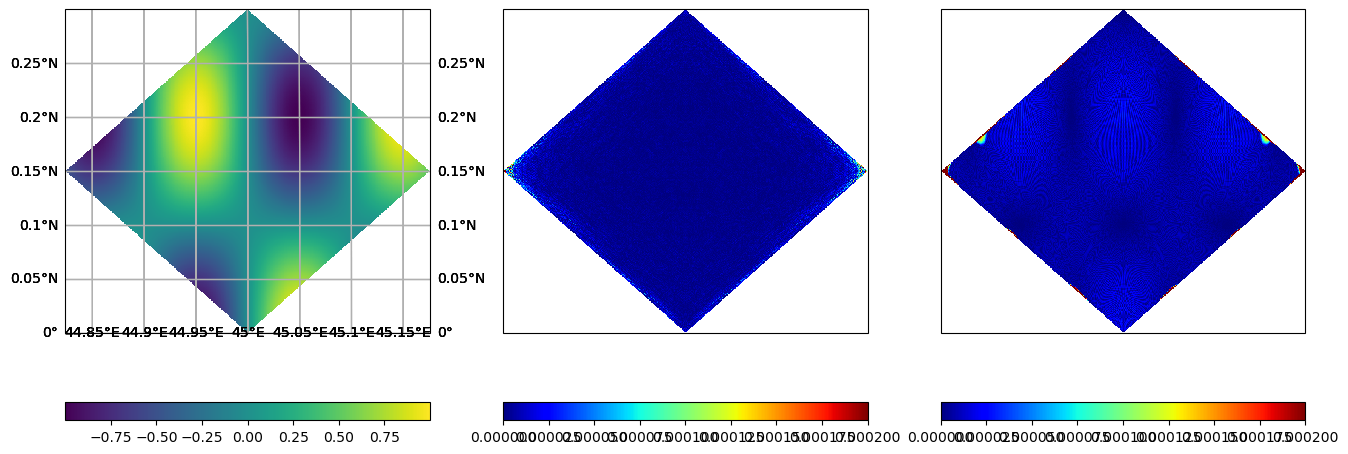

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    1, 3, subplot_kw={"projection": ccrs.Mollweide()}, figsize=(16, 6)
)

mappable = healpix_plot.plot(
    cell_ids, data, healpix_grid=healpix_grid, sampling_grid={"shape": 512}, ax=ax[0]
)

fig.colorbar(mappable, orientation="horizontal")
ax[0] = mappable.figure.axes[0]

ax[0].coastlines()
ax[0].gridlines(draw_labels="x")
ax[0].gridlines(draw_labels="y")

mappable = healpix_plot.plot(
    cell_ids, (abs(data-ds.data.values)), healpix_grid=healpix_grid, 
    sampling_grid={"shape": 512}, ax=ax[1], cmap='jet',vmin=0,vmax=0.0002,
)

fig.colorbar(mappable, orientation="horizontal")
ax[1] = mappable.figure.axes[0]

ax[1].coastlines()
ax[1].gridlines(draw_labels="x")
ax[1].gridlines(draw_labels="y")

mappable = healpix_plot.plot(
    cell_ids, (abs(data2-ds.data.values)), healpix_grid=healpix_grid, 
    sampling_grid={"shape": 512}, ax=ax[2], cmap='jet',vmin=0,vmax=0.0002,
)

fig.colorbar(mappable, orientation="horizontal")
ax[2] = mappable.figure.axes[0]

ax[2].coastlines()
ax[2].gridlines(draw_labels="x")
ax[2].gridlines(draw_labels="y")

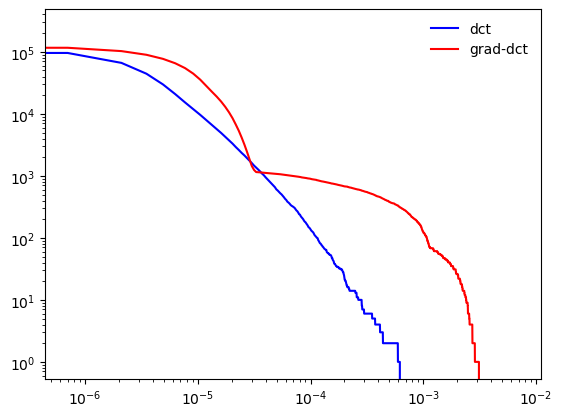

In [15]:
hy,hx=np.histogram(data-ds.data.values,bins=10000,range=[-7E-3,7E-3])
hy2,hx=np.histogram(data2-ds.data.values,bins=10000,range=[-7E-3,7E-3])

if ~do_grad:
    l1='dct'
    l2='grad-dct'
else:
    l2='dct'
    l1='grad-dct'
    
plt.plot((hx[1:]+hx[:-1])/2,np.sum(hy)-np.cumsum(abs(hy)),color='b',label=l1)
plt.plot((hx[1:]+hx[:-1])/2,np.sum(hy)-np.cumsum(abs(hy2)),color='r',label=l2)
plt.yscale('log')
plt.xscale('log')
plt.legend(frameon=0)